In [ ]:
# Setup & Import
import numpy as np
import matplotlib.pyplot as plt

!pip install -q tensorflow-datasets
import tensorflow as tf
from tensorflow import keras
import tensorflow_datasets as tfds
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
%pip install -q importlib-resources

In [ ]:
# Load dataset dan bagi menjadi 80% train, 10% validation, 10% test
(train_ds, val_ds, test_ds), info = tfds.load(
    "cats_vs_dogs",
    split=[
        "train[:80%]",
        "train[80%:90%]",
        "train[90%:]"
    ],
    as_supervised=True,
    with_info=True
)

print("Jumlah data train:", tf.data.experimental.cardinality(train_ds).numpy())
print("Jumlah data validation:", tf.data.experimental.cardinality(val_ds).numpy())
print("Jumlah data test:", tf.data.experimental.cardinality(test_ds).numpy())
print("Nama kelas:", info.features["label"].names)

Jumlah data train: 18610
Jumlah data validation: 2326
Jumlah data test: 2326
Nama kelas: ['cat', 'dog']


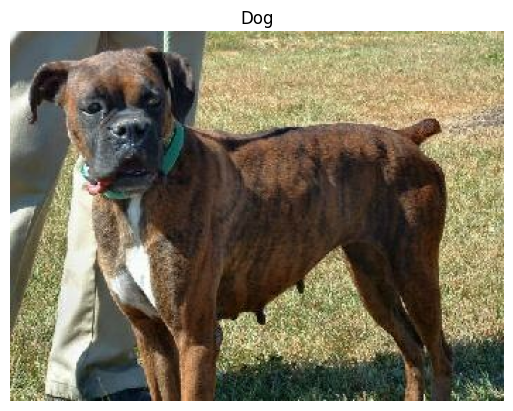

Image shape: (262, 350, 3)
Label: 1
Nama kelas: Dog


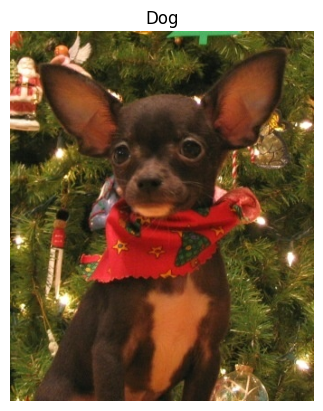

Image shape: (409, 336, 3)
Label: 1
Nama kelas: Dog


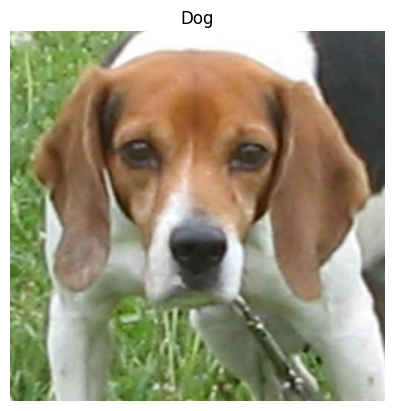

Image shape: (493, 500, 3)
Label: 1
Nama kelas: Dog


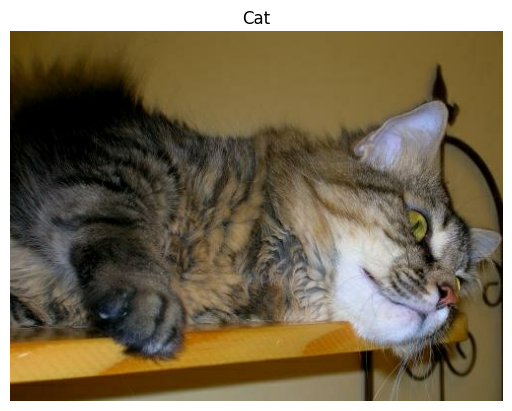

Image shape: (375, 500, 3)
Label: 0
Nama kelas: Cat


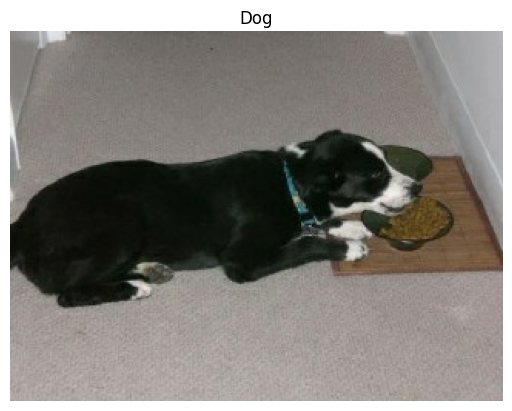

Image shape: (240, 320, 3)
Label: 1
Nama kelas: Dog


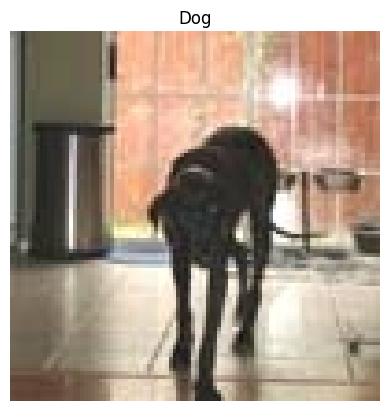

Image shape: (100, 100, 3)
Label: 1
Nama kelas: Dog


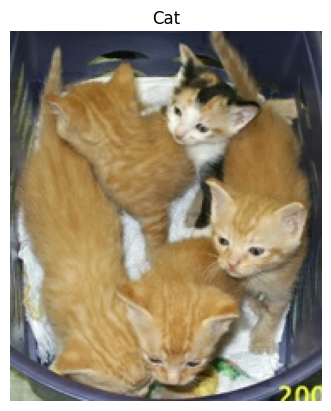

Image shape: (216, 182, 3)
Label: 0
Nama kelas: Cat


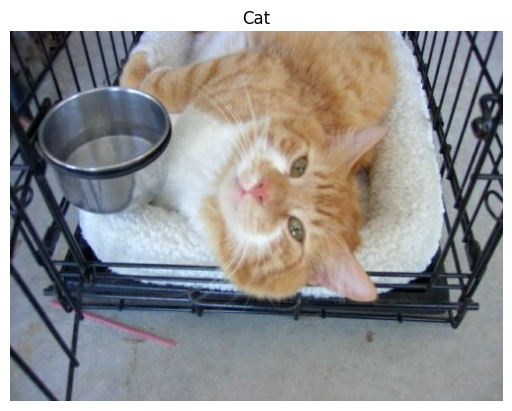

Image shape: (375, 500, 3)
Label: 0
Nama kelas: Cat


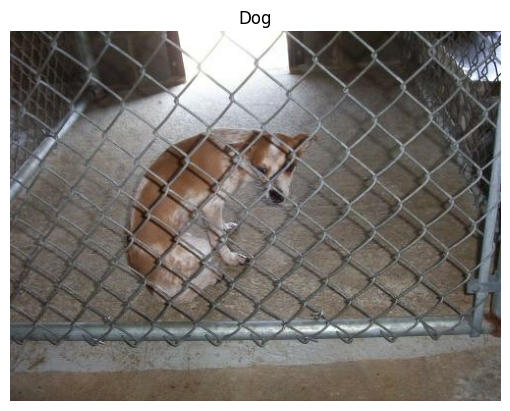

Image shape: (377, 500, 3)
Label: 1
Nama kelas: Dog


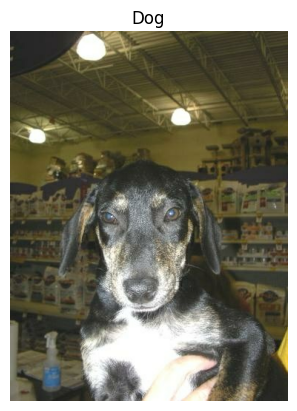

Image shape: (500, 375, 3)
Label: 1
Nama kelas: Dog


In [ ]:


class_names = ["Cat", "Dog"]

for image, label in train_ds.take(10):

    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")
    plt.show()

    print("Image shape:", image.shape)
    print("Label:", label.numpy())
    print("Nama kelas:", class_names[label.numpy()])

In [ ]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = (
    train_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)

Batch image shape: (32, 64, 64, 3)
Batch label shape: (32,)


In [ ]:
# Build Model: "Stack Otak"
model = keras.Sequential([
    # Input gambar: 128x128 RGB
    keras.Input(shape=(64, 64, 3)),

    # Convolutional layers: ekstraksi fitur gambar
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Ubah fitur menjadi vektor
    layers.Flatten(),

    # Fully connected layers
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),

    # Output: 2 kelas (cat dan dog)
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,905 (796.50 KB)

 Trainable params: 203,905 (796.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile: "ngasih aturan cara belajar"
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# Training Model
history = model.fit(
    train_ds,
    epochs=5,
    batch_size=32,
    validation_data=val_ds,
    verbose=1
)

Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 130s 220ms/step - accuracy: 0.6364 - loss: 0.6310 - val_accuracy: 0.7304 - val_loss: 0.5499
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 123s 209ms/step - accuracy: 0.7610 - loss: 0.5013 - val_accuracy: 0.7653 - val_loss: 0.4805
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 128s 218ms/step - accuracy: 0.8070 - loss: 0.4237 - val_accuracy: 0.7966 - val_loss: 0.4357
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 123s 209ms/step - accuracy: 0.8352 - loss: 0.3724 - val_accuracy: 0.8216 - val_loss: 0.4000
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 124s 212ms/step - accuracy: 0.8609 - loss: 0.3245 - val_accuracy: 0.8353 - val_loss: 0.3683


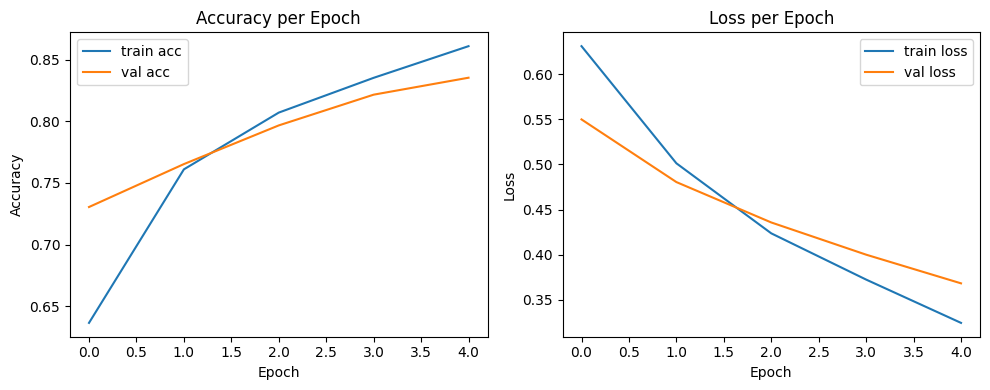

In [ ]:
# Visualisasi Accuracy dan Loss
plt.figure(figsize=(10, 4))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.title("Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluasi model pada data testing
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")


Test accuracy: 0.8469 | Test loss: 0.3518


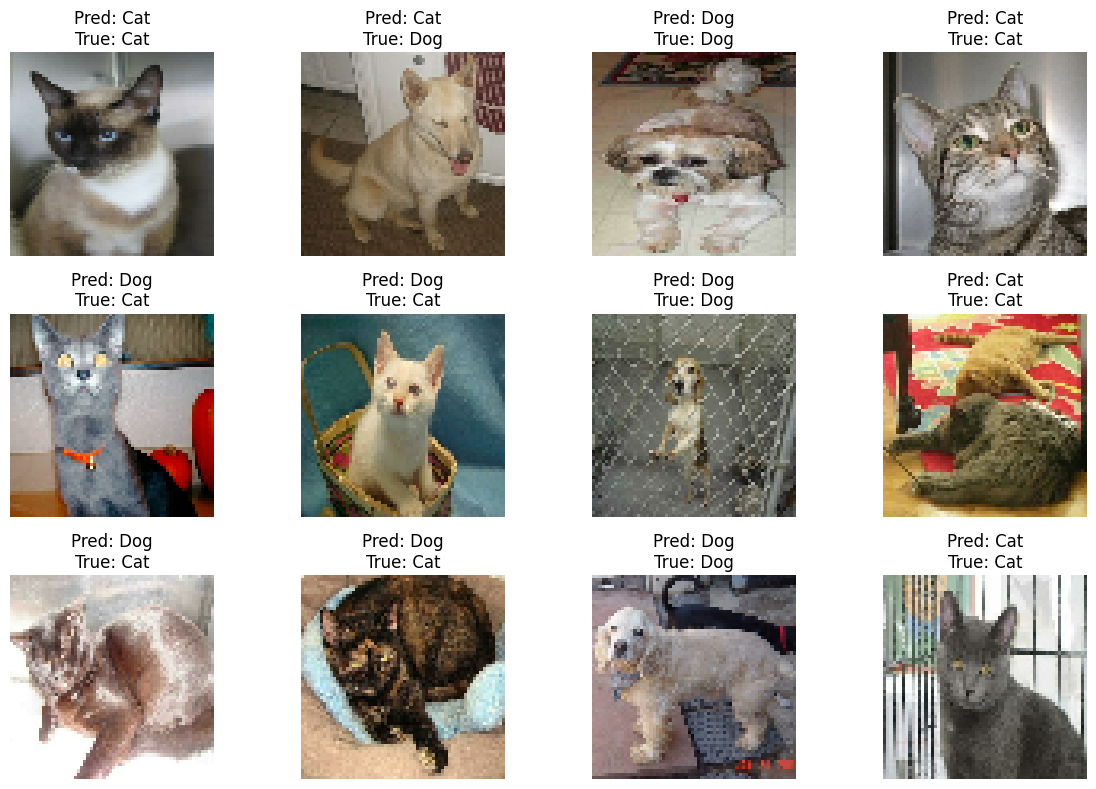

In [ ]:
# Ambil 12 gambar dari test dataset
for images, labels in test_ds.take(1):
    sample_images = images[:12]
    sample_labels = labels[:12].numpy()

# Prediksi probabilitas
pred_probs = model.predict(sample_images, verbose=0)

# Ubah probabilitas menjadi label 0 atau 1
pred_labels = (pred_probs.flatten() >= 0.5).astype(int)

class_names = ["Cat", "Dog"]

# Visualisasi hasil prediksi
plt.figure(figsize=(12, 8))

for i in range(len(sample_images)):
    plt.subplot(3, 4, i + 1)

    plt.imshow(sample_images[i].numpy())

    pred_name = class_names[pred_labels[i]]
    true_name = class_names[sample_labels[i]]

    title = f"Pred: {pred_name}\nTrue: {true_name}"
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Jumlah data testing: 2326
Jumlah salah: 356
Jumlah benar: 1970


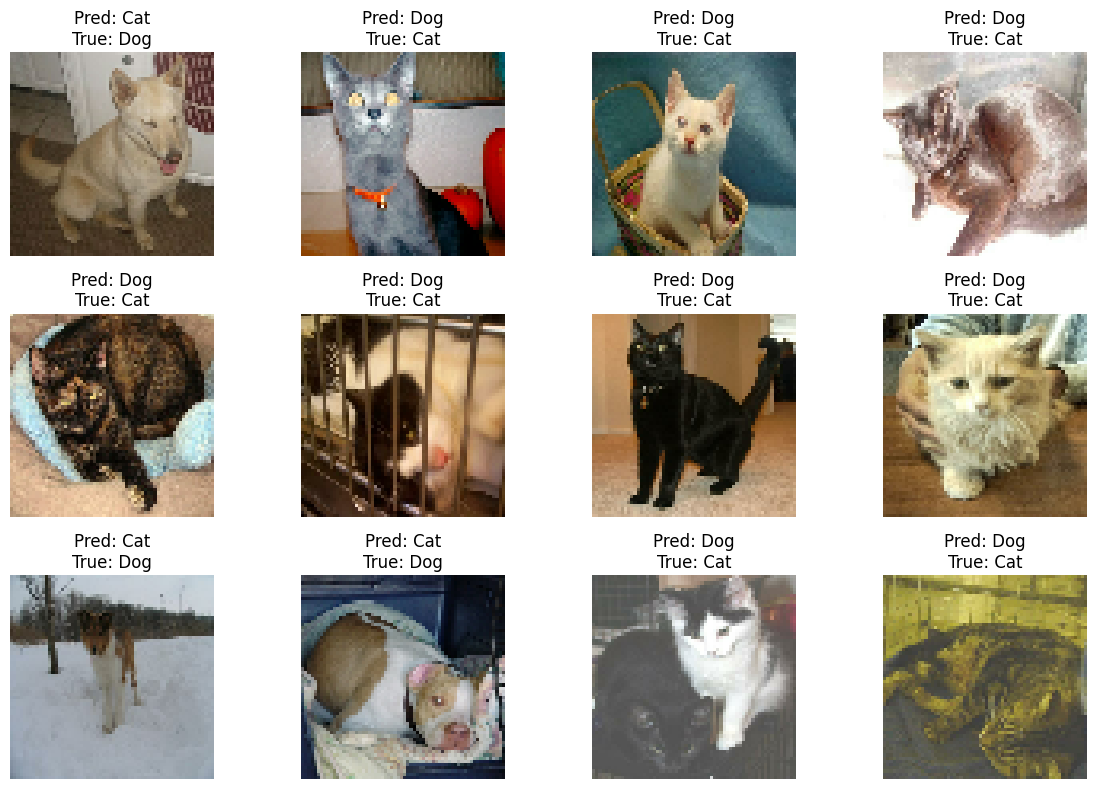

In [ ]:
# Prediksi seluruh data testing
pred_probs_all = model.predict(test_ds, verbose=0).flatten()

# Ubah probabilitas menjadi label 0 atau 1
pred_all = (pred_probs_all >= 0.5).astype(int)

# Ambil label asli dari test dataset
true_all = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Cari indeks prediksi yang salah
wrong_idx = np.where(pred_all != true_all)[0]

print("Jumlah data testing:", len(true_all))
print("Jumlah salah:", len(wrong_idx))
print("Jumlah benar:", len(true_all) - len(wrong_idx))

# Nama kelas
class_names = ["Cat", "Dog"]

# Tampilkan maksimal 12 contoh salah
plt.figure(figsize=(12, 8))

for j, idx in enumerate(wrong_idx[:12]):
    plt.subplot(3, 4, j + 1)

    # Ambil gambar berdasarkan indeks
    images_batch = idx // BATCH_SIZE
    image_idx = idx % BATCH_SIZE

    for images, labels in test_ds.skip(images_batch).take(1):
        image = images[image_idx].numpy()

    plt.imshow(image)
    plt.title(
        f"Pred: {class_names[pred_all[idx]]}\n"
        f"True: {class_names[true_all[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

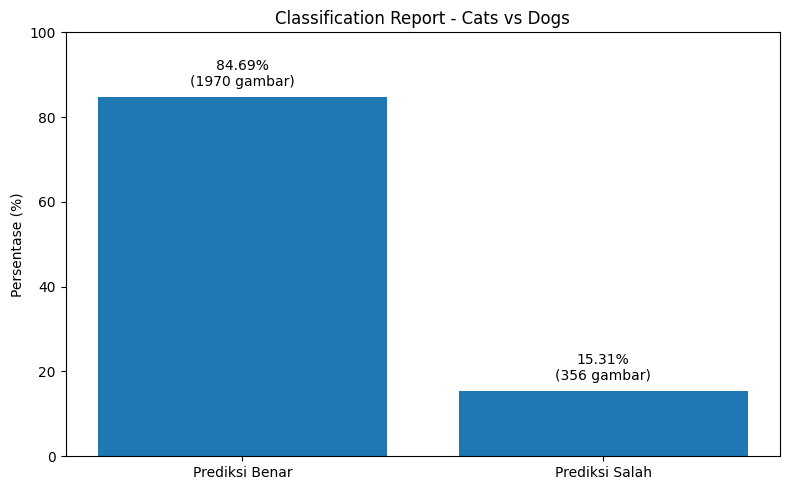

Total data testing : 2326
Prediksi benar     : 1970 (84.69%)
Prediksi salah     : 356 (15.31%)


In [ ]:
# Hitung persentase
total = len(true_all)
jumlah_benar = total - len(wrong_idx)
jumlah_salah = len(wrong_idx)

persen_benar = jumlah_benar / total * 100
persen_salah = jumlah_salah / total * 100

# Visualisasi report
plt.figure(figsize=(8, 5))

labels = ["Prediksi Benar", "Prediksi Salah"]
values = [persen_benar, persen_salah]

bars = plt.bar(labels, values)

plt.title("Classification Report - Cats vs Dogs")
plt.ylabel("Persentase (%)")
plt.ylim(0, 100)

# Tampilkan persentase dan jumlah gambar
for bar, persen, jumlah in zip(bars, values, [jumlah_benar, jumlah_salah]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{persen:.2f}%\n({jumlah} gambar)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print(f"Total data testing : {total}")
print(f"Prediksi benar     : {jumlah_benar} ({persen_benar:.2f}%)")
print(f"Prediksi salah     : {jumlah_salah} ({persen_salah:.2f}%)")

In [ ]:
history = model.fit(
    train_ds,
    epochs=10,
    batch_size=32,
    validation_data=val_ds,
    verbose=1
)

Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 126s 215ms/step - accuracy: 0.8805 - loss: 0.2858 - val_accuracy: 0.7954 - val_loss: 0.4561
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 129s 220ms/step - accuracy: 0.8949 - loss: 0.2517 - val_accuracy: 0.8203 - val_loss: 0.4273
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 123s 210ms/step - accuracy: 0.9068 - loss: 0.2229 - val_accuracy: 0.8439 - val_loss: 0.3985
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 124s 212ms/step - accuracy: 0.9218 - loss: 0.1891 - val_accuracy: 0.8332 - val_loss: 0.4136
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 127s 217ms/step - accuracy: 0.9321 - loss: 0.1673 - val_accuracy: 0.8422 - val_loss: 0.4601
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 126s 215ms/step - accuracy: 0.9418 - loss: 0.1473 - val_accuracy: 0.8469 - val_loss: 0.4669
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 124s 212ms/step - accuracy: 0.9462 - loss: 0.1328 - val_accuracy: 0.8512 - val_loss: 0.4774
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 123s 210ms/step - accuracy: 0.9575 -

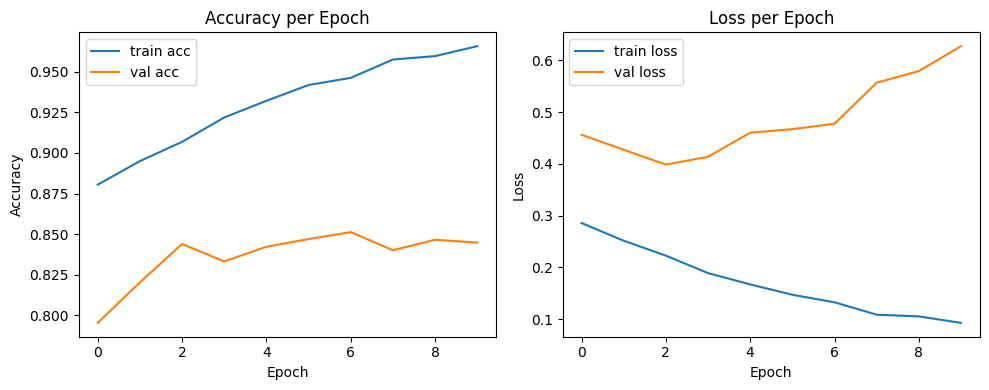

In [ ]:
# Visualisasi Accuracy dan Loss
plt.figure(figsize=(10, 4))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.title("Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# Evaluasi model pada data testing
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

Test accuracy: 0.8530 | Test loss: 0.5790


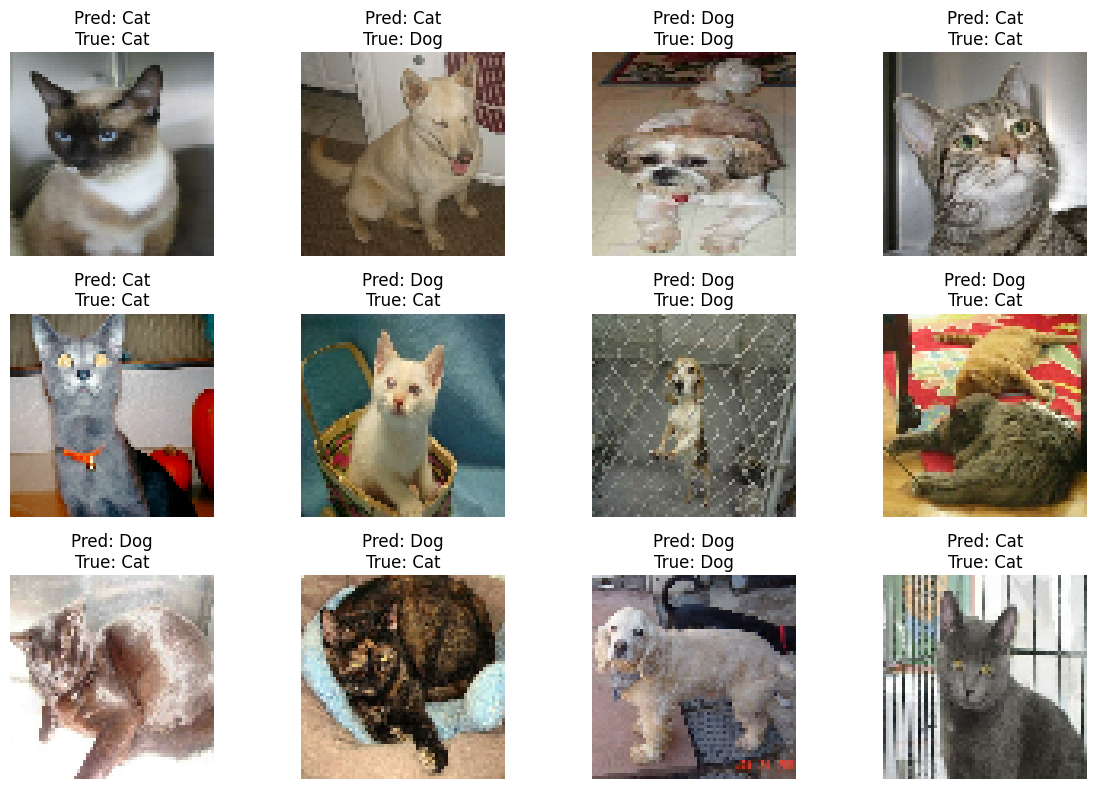

In [ ]:
# Ambil 12 gambar dari test dataset
for images, labels in test_ds.take(1):
    sample_images = images[:12]
    sample_labels = labels[:12].numpy()

# Prediksi probabilitas
pred_probs = model.predict(sample_images, verbose=0)

# Ubah probabilitas menjadi label 0 atau 1
pred_labels = (pred_probs.flatten() >= 0.5).astype(int)

class_names = ["Cat", "Dog"]

# Visualisasi hasil prediksi
plt.figure(figsize=(12, 8))

for i in range(len(sample_images)):
    plt.subplot(3, 4, i + 1)

    plt.imshow(sample_images[i].numpy())

    pred_name = class_names[pred_labels[i]]
    true_name = class_names[sample_labels[i]]

    title = f"Pred: {pred_name}\nTrue: {true_name}"
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Jumlah data testing: 2326
Jumlah salah: 342
Jumlah benar: 1984


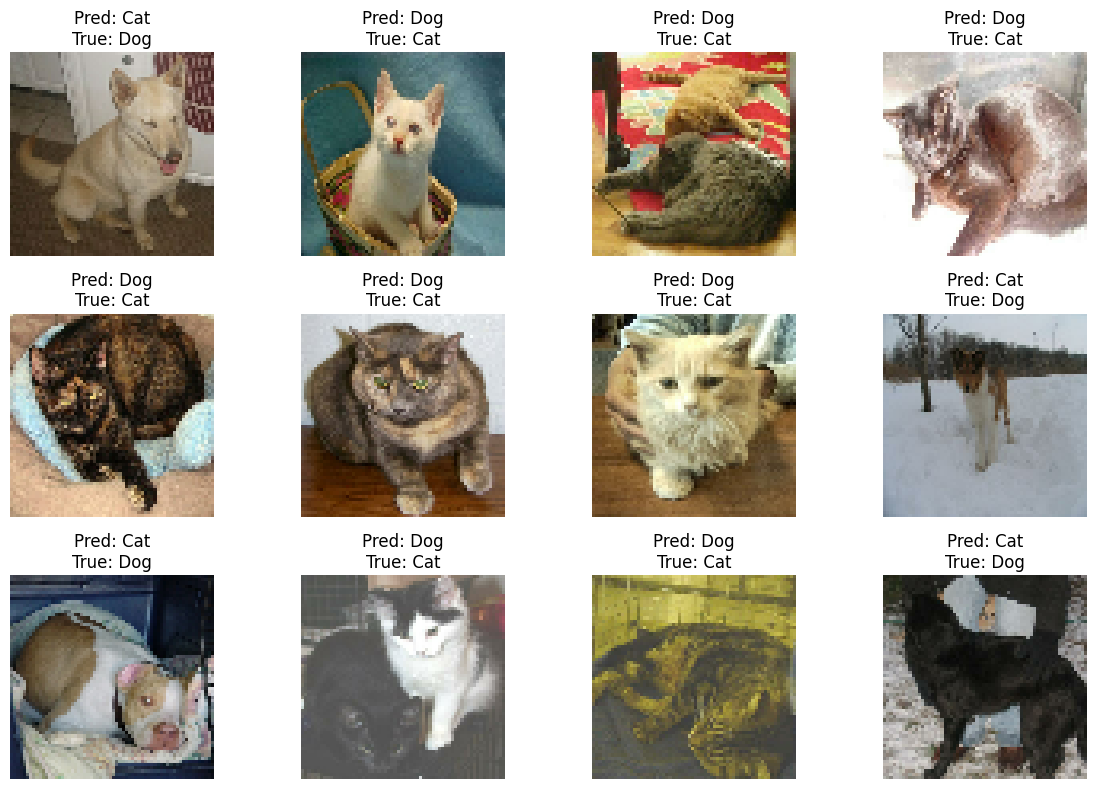

In [ ]:
# Prediksi seluruh data testing
pred_probs_all = model.predict(test_ds, verbose=0).flatten()

# Ubah probabilitas menjadi label 0 atau 1
pred_all = (pred_probs_all >= 0.5).astype(int)

# Ambil label asli dari test dataset
true_all = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Cari indeks prediksi yang salah
wrong_idx = np.where(pred_all != true_all)[0]

print("Jumlah data testing:", len(true_all))
print("Jumlah salah:", len(wrong_idx))
print("Jumlah benar:", len(true_all) - len(wrong_idx))

# Nama kelas
class_names = ["Cat", "Dog"]

# Tampilkan maksimal 12 contoh salah
plt.figure(figsize=(12, 8))

for j, idx in enumerate(wrong_idx[:12]):
    plt.subplot(3, 4, j + 1)

    # Ambil gambar berdasarkan indeks
    images_batch = idx // BATCH_SIZE
    image_idx = idx % BATCH_SIZE

    for images, labels in test_ds.skip(images_batch).take(1):
        image = images[image_idx].numpy()

    plt.imshow(image)
    plt.title(
        f"Pred: {class_names[pred_all[idx]]}\n"
        f"True: {class_names[true_all[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

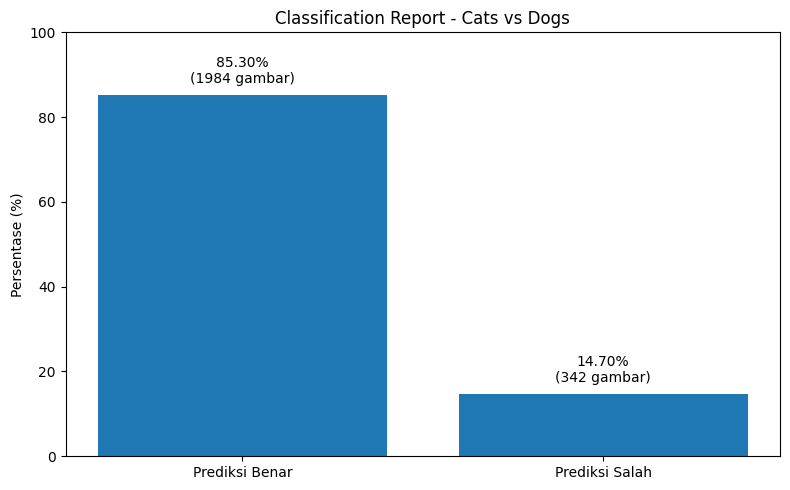

Total data testing : 2326
Prediksi benar     : 1984 (85.30%)
Prediksi salah     : 342 (14.70%)


In [ ]:
# Hitung persentase
total = len(true_all)
jumlah_benar = total - len(wrong_idx)
jumlah_salah = len(wrong_idx)

persen_benar = jumlah_benar / total * 100
persen_salah = jumlah_salah / total * 100

# Visualisasi report
plt.figure(figsize=(8, 5))

labels = ["Prediksi Benar", "Prediksi Salah"]
values = [persen_benar, persen_salah]

bars = plt.bar(labels, values)

plt.title("Classification Report - Cats vs Dogs")
plt.ylabel("Persentase (%)")
plt.ylim(0, 100)

# Tampilkan persentase dan jumlah gambar
for bar, persen, jumlah in zip(bars, values, [jumlah_benar, jumlah_salah]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{persen:.2f}%\n({jumlah} gambar)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print(f"Total data testing : {total}")
print(f"Prediksi benar     : {jumlah_benar} ({persen_benar:.2f}%)")
print(f"Prediksi salah     : {jumlah_salah} ({persen_salah:.2f}%)")

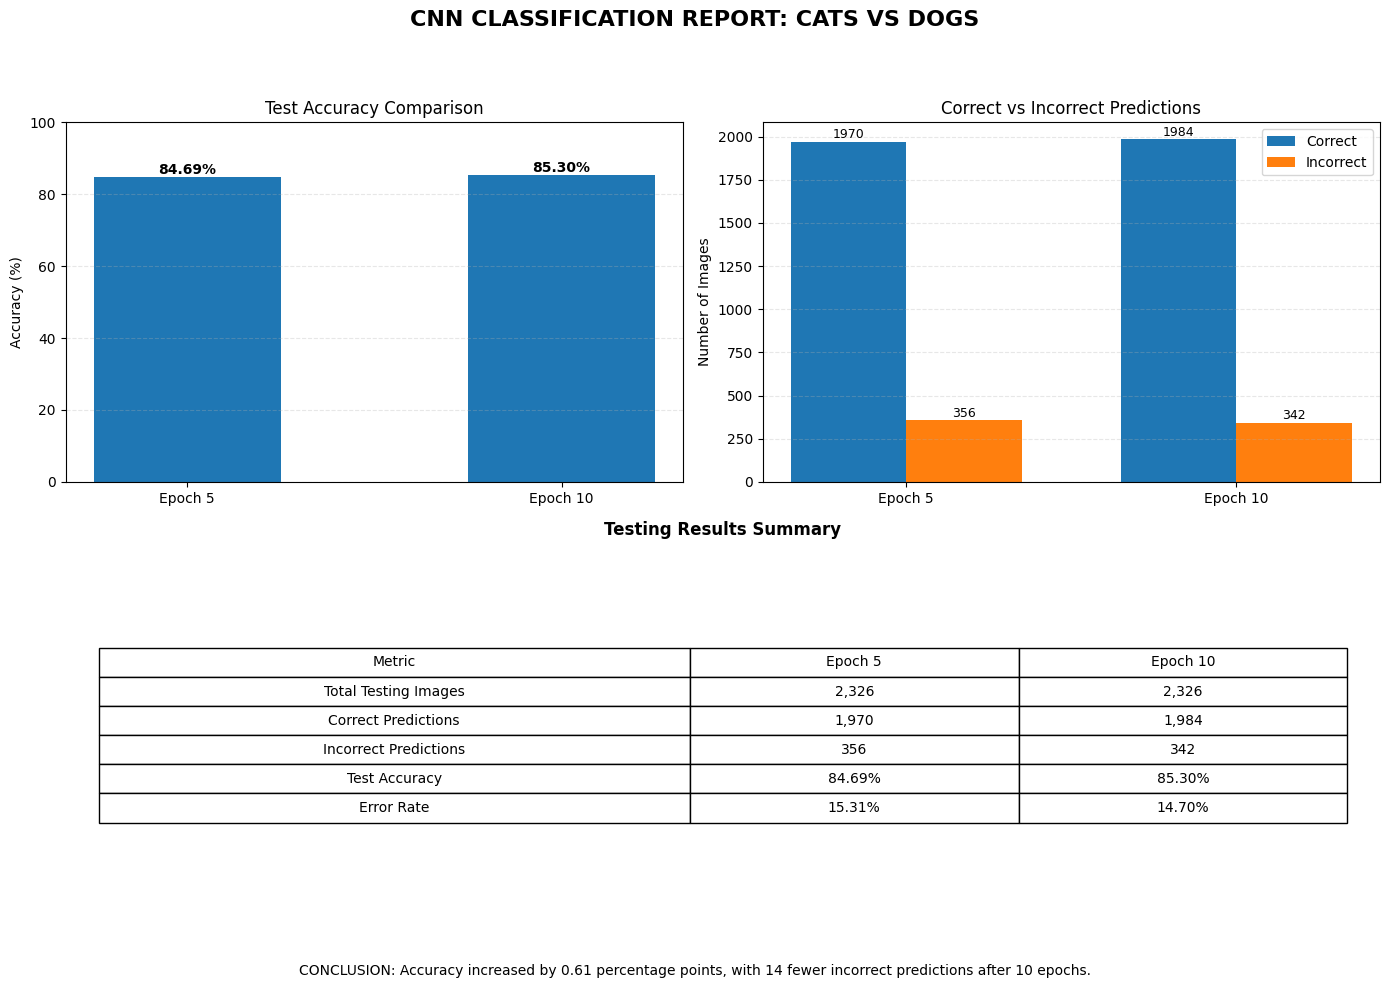

=== FINAL REPORT ===
Epoch 5  Accuracy : 84.69%
Epoch 10 Accuracy : 85.30%
Accuracy increase: +0.61 percentage points
Errors reduced   : 14 images


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Data hasil eksperimen
epochs = ["Epoch 5", "Epoch 10"]
total = [2326, 2326]
benar = [1970, 1984]
salah = [356, 342]
akurasi = [84.69, 85.30]
error_rate = [15.31, 14.70]

# Buat report visual
fig = plt.figure(figsize=(14, 10))
fig.suptitle(
    "CNN CLASSIFICATION REPORT: CATS VS DOGS",
    fontsize=16,
    fontweight="bold"
)

# 1. Grafik akurasi
ax1 = fig.add_subplot(2, 2, 1)
bars = ax1.bar(epochs, akurasi, width=0.5)

ax1.set_title("Test Accuracy Comparison")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(0, 100)
ax1.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, akurasi):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

# 2. Grafik prediksi benar dan salah
ax2 = fig.add_subplot(2, 2, 2)
x = np.arange(len(epochs))
width = 0.35

b1 = ax2.bar(x - width/2, benar, width, label="Correct")
b2 = ax2.bar(x + width/2, salah, width, label="Incorrect")

ax2.set_title("Correct vs Incorrect Predictions")
ax2.set_xticks(x)
ax2.set_xticklabels(epochs)
ax2.set_ylabel("Number of Images")
ax2.legend()
ax2.grid(axis="y", linestyle="--", alpha=0.3)

for bars_group in [b1, b2]:
    for bar in bars_group:
        ax2.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 20,
            f"{int(bar.get_height())}",
            ha="center",
            fontsize=9
        )

# 3. Tabel hasil pengujian
ax3 = fig.add_subplot(2, 1, 2)
ax3.axis("off")
ax3.set_title("Testing Results Summary", fontweight="bold", pad=15)

table_data = [
    ["Total Testing Images", "2,326", "2,326"],
    ["Correct Predictions", "1,970", "1,984"],
    ["Incorrect Predictions", "356", "342"],
    ["Test Accuracy", "84.69%", "85.30%"],
    ["Error Rate", "15.31%", "14.70%"],
]

table = ax3.table(
    cellText=table_data,
    colLabels=["Metric", "Epoch 5", "Epoch 10"],
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.45, 0.25, 0.25]
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)

# Kesimpulan
fig.text(
    0.5, 0.015,
    "CONCLUSION: Accuracy increased by 0.61 percentage points, "
    "with 14 fewer incorrect predictions after 10 epochs.",
    ha="center",
    fontsize=10,
    wrap=True
)

plt.tight_layout(rect=[0, 0.06, 1, 0.94])
plt.show()

# Ringkasan angka
print("=== FINAL REPORT ===")
print(f"Epoch 5  Accuracy : {akurasi[0]:.2f}%")
print(f"Epoch 10 Accuracy : {akurasi[1]:.2f}%")
print(f"Accuracy increase: +{akurasi[1] - akurasi[0]:.2f} percentage points")
print(f"Errors reduced   : {salah[0] - salah[1]} images")
